## Homework 4: Numerical differentiation

**Course title:** Computer Simulation Methods in Physics (Phys 4071/5071; Fall 2025)  
**This homework assignment is due September 24, 2025, at 8 am.**   
(Submission via the shared `GitHub` repository.)

**Before you submit your homework, make sure that you click `Kernel > Restart & Run All`**.

## Finite differencing

Differentiate the functions $f(x) = \cos x$ and $g(x) = \sqrt{x}$ at $x=0.1, 1.0$, and
$30.0$ using forward, backward, and central finite differencing.

* Write your own `Python` functions. Do not use packages that already implement finite difference methods.
* Print out the derivative and its relative error $\varepsilon$ as a 
 function of $h$. Reduce the step size $h$ until it equals machine precision, $h \approx
\epsilon_m$,
* Plot $\log_{10} |\varepsilon|$ versus $\log_{10} h$, and check whether
the number of decimal places obtained agrees with the estimates in the text.
* See if you can identify truncation errors at large $h$ and the roundoff
error at small $h$ in your plot. Do the slopes agree with the predictions from the book?

In [1]:
# 1.) Part A-B (bullets 1-2) 

import math
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 


def f(x): 
    '''
    Function f is defined as cosine and can be evaluated at certain x's or gridpoints of x. 

    Parameters
    ----------
    x : int, float, or numpy array 
        Value or set of values that define f(x). 

    Returns
    -------
    int, float, or numpy array 
        Return the value or values of f(x) per each x. 
    '''
    return np.cos(x) 


def g(x): 
    '''
    Function g is defined as square root and can be evaluated at certain x's or gridpoints of x. 

    Parameters
    ----------
    x : int, float, or numpy array 
        Value or set of values that define g(x). 

    Returns
    -------
    int, float, or numpy array 
        Return the value or values of g(x) per each x. 
    '''
    return np.sqrt(x) 



def f_prime(x): 
    '''
     Derivative function f is defined as -sine and can be evaluated at certain x's or gridpoints of x. 

    Parameters
    ----------
    x : int, float, or numpy array 
        Value or set of values that define f'(x). 

    Returns
    -------
    int, float, or numpy array 
        Return the value or values of f'(x) per each x. 
    '''
    return (-1.0)*np.sin(x) 

def g_prime(x): 
    '''
     Derivative function g is defined as -sine and can be evaluated at certain x's or gridpoints of x. 

    Parameters
    ----------
    x : int, float, or numpy array 
        Value or set of values that define g'(x). 

    Returns
    -------
    int, float, or numpy array 
        Return the value or values of g'(x) per each x. 
    '''
    return (0.5)*pow(x, -0.5)




def central_diff(f, x, h):
    '''
    Computes the central derivative for a certain x-value and specific step size.  

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 
    x : float 
        Value to which the central derivative will be applied. 
    h : float
        Step size of the central derivative.

    Returns
    -------
    float
        Approximation of the derivative evaluated at x using the central method.
    '''
    return (f(x + h/2) - f(x - h/2)) / h


def forward_diff(f, x, h):
    '''
    Computes the forward derivative for a certain x-value and specific step size.  

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 
    x : float 
        Value to which the forward derivative will be applied. 
    h : float
        Step size of the forward derivative.

    Returns
    -------
    float
        Approximation of the derivative evaluated at x using the forward method.
    '''
    return 2 * (f(x + h/2) - f(x)) / h


def backward_diff(f, x, h):
    '''
    Computes the backward derivative for a certain x-value and specific step size.  

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 
    x : float 
        Value to which the backward derivative will be applied. 
    h : float
        Step size of the backward derivative.

    Returns
    -------
    float
        Approximation of the derivative evaluated at x using the backward method.
    '''
    return 2 * (f(x) - f(x - h/2)) / h



def der_Table(W, W_prime, x): 
    ''' Displays and computes the derivative methods, step sizes, and relative errors of each function case and x. 

    Parameters
    ----------
    W : function
        Python function used per data stream.
    W_prime: function 
        Python defined derivatives of test functions of choice
    x: float 
        specifies data points to evaluate the derivatives.
    Returns
    -------
    Panda DataFrame
        Returns a pandas DataFrame table that displays the step sizes, relative errors, and each differentiation scheme. 
        
    '''
    Table = [] 
    for i in np.arange(1, 18, 1):
        h = 0.1**i
        Forward_D = forward_diff(W, x, h)
        Backward_D = backward_diff(W, x, h)
        Central_D = central_diff(W, x, h)
        rel_F = abs(Forward_D - W_prime(x))/abs(W_prime(x))
        rel_C = abs(Central_D - W_prime(x))/abs(W_prime(x))
        rel_B = abs(Backward_D - W_prime(x))/abs(W_prime(x))
        Table.append({
            "index": i,
            "h": f"{h:1.15e}", 
            "Forward": f"{Forward_D:1.15e}", 
            "Backward": f"{Backward_D:1.15e}", 
            "Central": f"{Central_D:1.15e}", 
            "eps_F": f"{rel_F:1.15e}", 
            "eps_C": f"{rel_C:1.15e}", 
            "eps_B": f"{rel_B:1.15e}"
        })
    return pd.DataFrame(Table).to_string(index=False)
    


print("f(x = 0.1) case:")
print(der_Table(f, f_prime, 0.1))
print("\nf(x = 1.0) case:")
print(der_Table(f, f_prime, 1.0))
print("\nf(x = 30.0) case:")
print(der_Table(f, f_prime, 30.0))
print("\ng(x = 0.1) case:")
print(der_Table(g, g_prime, 0.1))
print("\ng(x = 1.0) case:")
print(der_Table(g, g_prime, 1.0))
print("\ng(x = 30.0) case:")
print(der_Table(g, g_prime, 30.0))









f(x = 0.1) case:
 index                     h                Forward               Backward                Central                 eps_F                 eps_C                 eps_B
     1 1.000000000000000e-01 -1.246617468396716e-01 -7.492190233880924e-02 -9.979182458924041e-02 2.486975907143036e-01 4.166145864253412e-04 2.495308198871543e-01
     2 1.000000000000000e-02 -1.023205059056842e-01 -9.734549544389014e-02 -9.983300067478716e-02 2.491239248732103e-02 4.166661374162130e-06 2.492072581006935e-02
     3 1.000000000000000e-03 -1.000821635233073e-01 -9.958466145087994e-02 -9.983341248709363e-02 2.491619387916282e-03 4.166675516844021e-08 2.491702721426619e-03
     4 1.000000000000000e-04 -9.985829171110792e-02 -9.980854150049011e-02 -9.983341660579902e-02 2.491657113946917e-04 4.109760018053283e-10 2.491665333466954e-04
     5 1.000000000000000e-05 -9.983590416595686e-02 -9.983092912335675e-02 -9.983341664465681e-02 2.491669835870269e-05 2.174969573231823e-11 2.491674185809415e-05

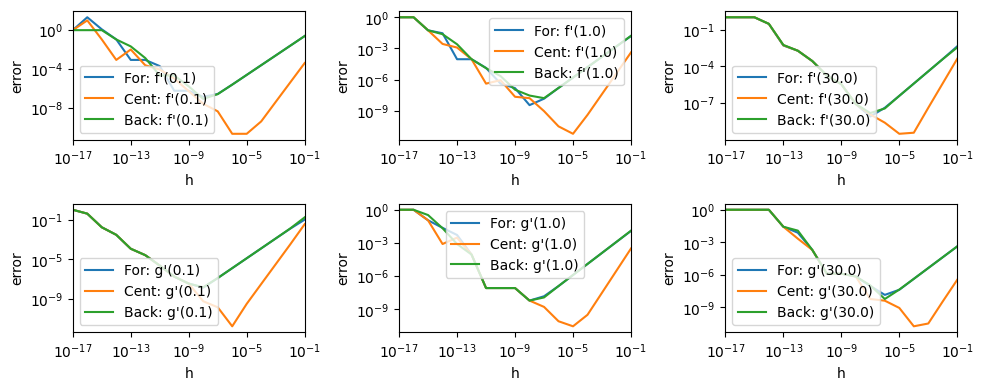

In [2]:
# 1.) Part C (bullets 3) 

import math
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

# 1 row, 3 columns of subplots
fig, axes = plt.subplots(2, 3, figsize=(10, 4))



#f(X = 0.1) and g(X = 0.1) plotting Case: 

h_vals = [] 
F_err_For = [] 
F_err_C = [] 
F_err_B = [] 
G_err_For = [] 
G_err_B = [] 
G_err_C = [] 

for i in np.arange(1, 18, 1):
    h = 0.1**i
    F_Forward_D = forward_diff(f, 0.1, h)
    F_Backward_D = backward_diff(f, 0.1, h)
    F_Central_D = central_diff(f, 0.1, h)
    G_Forward_D = forward_diff(g, 0.1, h)
    G_Backward_D = backward_diff(g, 0.1, h)
    G_Central_D = central_diff(g, 0.1, h)

    F_rel_F = abs(F_Forward_D - f_prime(0.1))/abs(f_prime(0.1))
    F_rel_C = abs(F_Central_D - f_prime(0.1))/abs(f_prime(0.1))
    F_rel_B = abs(F_Backward_D - f_prime(0.1))/abs(f_prime(0.1))
    G_rel_F = abs(G_Forward_D - g_prime(0.1))/abs(g_prime(0.1))
    G_rel_C = abs(G_Central_D - g_prime(0.1))/abs(g_prime(0.1))
    G_rel_B = abs(G_Backward_D - g_prime(0.1))/abs(g_prime(0.1))

    h_vals.append(h)
    F_err_For.append(F_rel_F)
    F_err_C.append(F_rel_C)
    F_err_B.append(F_rel_B)
    G_err_For.append(G_rel_F)
    G_err_C.append(G_rel_C)
    G_err_B.append(G_rel_B)
    

# f(x = 0.1)
axes[0,0].loglog(h_vals, F_err_For, label = "For: f'(0.1)")    
axes[0,0].loglog(h_vals, F_err_C, label = "Cent: f'(0.1)")   
axes[0,0].loglog(h_vals, F_err_B, label = "Back: f'(0.1)")   
axes[0,0].set_xlabel("h")
axes[0,0].set_ylabel("error")
axes[0,0].set_xlim(h_vals[-1], h_vals[0])
axes[0,0].legend(loc="best")

# g(x = 0.1)
axes[1,0].loglog(h_vals, G_err_For, label = "For: g'(0.1)")   
axes[1,0].loglog(h_vals, G_err_C, label = "Cent: g'(0.1)")   
axes[1,0].loglog(h_vals, G_err_B, label = "Back: g'(0.1)") 
axes[1,0].set_xlabel("h")
axes[1,0].set_ylabel("error")
axes[1,0].set_xlim(h_vals[-1], h_vals[0])
axes[1,0].legend(loc="best")


#f(X = 1.0) and g(X = 1.0) plotting Case: 

h_vals1 = [] 
F_err_For1 = [] 
F_err_C1 = [] 
F_err_B1 = [] 
G_err_For1 = [] 
G_err_B1 = [] 
G_err_C1 = [] 

for i in np.arange(1, 18, 1):
    h1 = 0.1**i
    F_Forward_D1 = forward_diff(f, 1.0, h1)
    F_Backward_D1 = backward_diff(f, 1.0, h1)
    F_Central_D1 = central_diff(f, 1.0, h1)
    G_Forward_D1 = forward_diff(g, 1.0, h1)
    G_Backward_D1 = backward_diff(g, 1.0, h1)
    G_Central_D1 = central_diff(g, 1.0, h1)

    F_rel_F1 = abs(F_Forward_D1 - f_prime(1.0))/abs(f_prime(1.0))
    F_rel_C1 = abs(F_Central_D1 - f_prime(1.0))/abs(f_prime(1.0))
    F_rel_B1 = abs(F_Backward_D1 - f_prime(1.0))/abs(f_prime(1.0))
    G_rel_F1 = abs(G_Forward_D1 - g_prime(1.0))/abs(g_prime(1.0))
    G_rel_C1 = abs(G_Central_D1 - g_prime(1.0))/abs(g_prime(1.0))
    G_rel_B1 = abs(G_Backward_D1 - g_prime(1.0))/abs(g_prime(1.0))

    h_vals1.append(h1)
    F_err_For1.append(F_rel_F1)
    F_err_C1.append(F_rel_C1)
    F_err_B1.append(F_rel_B1)
    G_err_For1.append(G_rel_F1)
    G_err_C1.append(G_rel_C1)
    G_err_B1.append(G_rel_B1)
    

# f(x = 1.0)
axes[0,1].loglog(h_vals1, F_err_For1, label = "For: f'(1.0)")    
axes[0,1].loglog(h_vals1, F_err_C1, label = "Cent: f'(1.0)")   
axes[0,1].loglog(h_vals1, F_err_B1, label = "Back: f'(1.0)")   
axes[0,1].set_xlabel("h")
axes[0,1].set_ylabel("error")
axes[0,1].set_xlim(h_vals1[-1], h_vals1[0])
axes[0,1].legend(loc="best")

# g(x = 1.0)
axes[1,1].loglog(h_vals1, G_err_For1, label = "For: g'(1.0)")   
axes[1,1].loglog(h_vals1, G_err_C1, label = "Cent: g'(1.0)")   
axes[1,1].loglog(h_vals1, G_err_B1, label = "Back: g'(1.0)") 
axes[1,1].set_xlabel("h")
axes[1,1].set_ylabel("error")
axes[1,1].set_xlim(h_vals1[-1], h_vals1[0])
axes[1,1].legend(loc="best")


#f(X = 30.0) and g(X = 30.0) plotting Case: 

h_vals2 = [] 
F_err_For2 = [] 
F_err_C2 = [] 
F_err_B2 = [] 
G_err_For2 = [] 
G_err_B2 = [] 
G_err_C2 = [] 

for i in np.arange(1, 18, 1):
    h2 = 0.1**i
    F_Forward_D2 = forward_diff(f, 30.0, h2)
    F_Backward_D2 = backward_diff(f, 30.0, h2)
    F_Central_D2 = central_diff(f, 30.0, h2)
    G_Forward_D2 = forward_diff(g, 30.0, h2)
    G_Backward_D2 = backward_diff(g, 30.0, h2)
    G_Central_D2 = central_diff(g, 30.0, h2)

    F_rel_F2 = abs(F_Forward_D2 - f_prime(30.0))/abs(f_prime(30.0))
    F_rel_C2 = abs(F_Central_D2 - f_prime(30.0))/abs(f_prime(30.0))
    F_rel_B2 = abs(F_Backward_D2 - f_prime(30.0))/abs(f_prime(30.0))
    G_rel_F2 = abs(G_Forward_D2 - g_prime(30.0))/abs(g_prime(30.0))
    G_rel_C2 = abs(G_Central_D2 - g_prime(30.0))/abs(g_prime(30.0))
    G_rel_B2 = abs(G_Backward_D2 - g_prime(30.0))/abs(g_prime(30.0))

    h_vals2.append(h2)
    F_err_For2.append(F_rel_F2)
    F_err_C2.append(F_rel_C2)
    F_err_B2.append(F_rel_B2)
    G_err_For2.append(G_rel_F2)
    G_err_C2.append(G_rel_C2)
    G_err_B2.append(G_rel_B2)
    
# f(x = 30.0)
axes[0,2].loglog(h_vals2, F_err_For2, label = "For: f'(30.0)")    
axes[0,2].loglog(h_vals2, F_err_C2, label = "Cent: f'(30.0)")   
axes[0,2].loglog(h_vals2, F_err_B2, label = "Back: f'(30.0)")   
axes[0,2].set_xlabel("h")
axes[0,2].set_ylabel("error")
axes[0,2].set_xlim(h_vals2[-1], h_vals2[0])
axes[0,2].legend(loc="best")

# g(x = 30.0)
axes[1,2].loglog(h_vals2, G_err_For2, label = "For: g'(30.0)")   
axes[1,2].loglog(h_vals2, G_err_C2, label = "Cent: g'(30.0)")   
axes[1,2].loglog(h_vals2, G_err_B2, label = "Back: g'(30.0)") 
axes[1,2].set_xlabel("h")
axes[1,2].set_ylabel("error")
axes[1,2].set_xlim(h_vals2[-1], h_vals2[0])
axes[1,2].legend(loc="best")



plt.tight_layout()
plt.show()












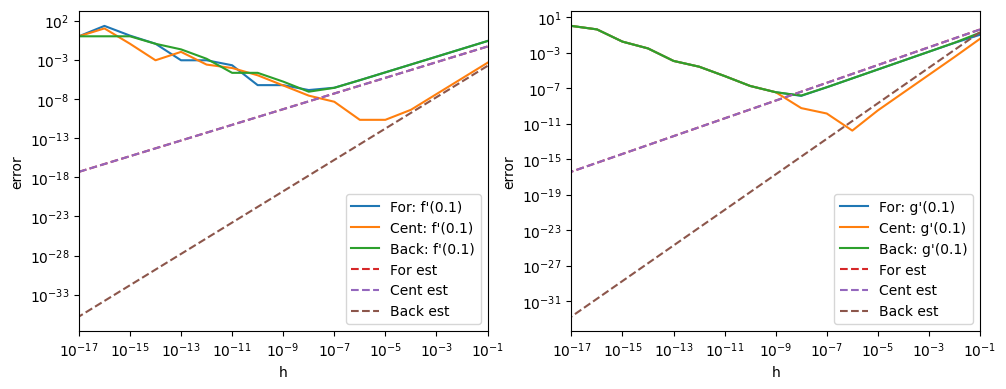

In [3]:
# 1.) Part C (bullets 3) (Comparisons of relative errors and error estimates from each method) 



"""

The approach I'm going to use is to compare relative errors 
and approximation errors defined by each method (Forward, Backward, and Central) by plotting 
all in one per each f and g function, and by doing it for the x = 0.1 case. 


"""



import math
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 





def f_Double_prime(x): 
    '''
     2nd derivative function f is defined as -sine and can be evaluated at certain x's or gridpoints of x. 

    Parameters
    ----------
    x : int, float, or numpy array 
        Value or set of values that define f''(x). 

    Returns
    -------
    int, float, or numpy array 
        Return the value or values of f''(x) per each x. 
    '''
    return (-1.0)*np.cos(x) 

def g_Double_prime(x): 
    '''
     2nd derivative function g is defined as -sine and can be evaluated at certain x's or gridpoints of x. 

    Parameters
    ----------
    x : int, float, or numpy array 
        Value or set of values that define g''(x). 

    Returns
    -------
    int, float, or numpy array 
        Return the value or values of g''(x) per each x. 
    '''
    return (-0.25)*pow(x, (-3.0/2.0))


def f_Triple_prime(x): 
    '''
     3rd derivative function f is defined as -sine and can be evaluated at certain x's or gridpoints of x. 

    Parameters
    ----------
    x : int, float, or numpy array 
        Value or set of values that define d^3f(x). 

    Returns
    -------
    int, float, or numpy array 
        Return the value or values of d^3f(x) per each x. 
    '''
    return (1.0)*np.sin(x) 

def g_Triple_prime(x): 
    '''
     3rd derivative function g is defined as -sine and can be evaluated at certain x's or gridpoints of x. 

    Parameters
    ----------
    x : int, float, or numpy array 
        Value or set of values that defines d^3g(x). 

    Returns
    -------
    int, float, or numpy array 
        Return the value or values of d^3g(x) per each x. 
    '''
    return (3.0/8.0)*pow(x, (-5.0/2.0))






def Approx_error(h, W, method="central"):
    '''
    Leading-order approximation error for finite-difference 1st-derivative schemes.

    Parameters
    ----------
    h : float
        Stepsize.
    method : {"forward", "backward", "central"}
        Which finite-difference method.
    W : function
        The derivative function for the leading error term:
        - forward/backward: pass the *second* derivative (e.g., f_Double_prime)
        - central: pass the *third* derivative (e.g., f_Triple_prime)

    Returns
    -------
    function
        A callable err(x) that evaluates the approximation error at x.
    '''
    if method == "central":
        return lambda x: (h**2 / 6.0) * W(x)
    elif method == "forward":
        return lambda x: (h / 2.0) * W(x)
    elif method == "backward":
        return lambda x: (-h / 2.0) * W(x)
    else:
        raise ValueError("method must be 'forward', 'backward', or 'central'")


# 1 row, 2 columns of subplots
fig1, axes1 = plt.subplots(1, 2, figsize=(10, 4))



#f(X = 0.1) and g(X = 0.1) plotting Case: 

h_vals = [] 
F_err_For = [] 
F_err_C = [] 
F_err_B = [] 
G_err_For = [] 
G_err_B = [] 
G_err_C = [] 
F_F_approx = [] 
F_C_approx = [] 
F_B_approx = [] 
G_F_approx = [] 
G_C_approx = [] 
G_B_approx = [] 


for i in np.arange(1, 18, 1):
    h = 0.1**i
    F_Forward_D = forward_diff(f, 0.1, h)
    F_Backward_D = backward_diff(f, 0.1, h)
    F_Central_D = central_diff(f, 0.1, h)
    G_Forward_D = forward_diff(g, 0.1, h)
    G_Backward_D = backward_diff(g, 0.1, h)
    G_Central_D = central_diff(g, 0.1, h)

    F_rel_F = abs(F_Forward_D - f_prime(0.1))/abs(f_prime(0.1))
    F_rel_C = abs(F_Central_D - f_prime(0.1))/abs(f_prime(0.1))
    F_rel_B = abs(F_Backward_D - f_prime(0.1))/abs(f_prime(0.1))
    G_rel_F = abs(G_Forward_D - g_prime(0.1))/abs(g_prime(0.1))
    G_rel_C = abs(G_Central_D - g_prime(0.1))/abs(g_prime(0.1))
    G_rel_B = abs(G_Backward_D - g_prime(0.1))/abs(g_prime(0.1))


    F_F_app = abs(Approx_error(h, method="forward",  W=f_Double_prime)(0.1))   
    F_B_app = abs(Approx_error(h, method="backward", W=f_Double_prime)(0.1))   
    F_C_app = abs(Approx_error(h, method="central",  W=f_Triple_prime)(0.1))   
    G_F_app = abs(Approx_error(h, method="forward",  W=g_Double_prime)(0.1))   
    G_B_app = abs(Approx_error(h, method="backward", W=g_Double_prime)(0.1))   
    G_C_app = abs(Approx_error(h, method="central",  W=g_Triple_prime)(0.1))   


    h_vals.append(h)
    F_err_For.append(F_rel_F)
    F_err_C.append(F_rel_C)
    F_err_B.append(F_rel_B)
    G_err_For.append(G_rel_F)
    G_err_C.append(G_rel_C)
    G_err_B.append(G_rel_B)
    F_F_approx.append(F_F_app)
    F_C_approx.append(F_B_app)
    F_B_approx.append(F_C_app)
    G_F_approx.append(G_F_app)
    G_C_approx.append(G_B_app)
    G_B_approx.append(G_C_app)
    

# f(x = 0.1)
axes1[0].loglog(h_vals, F_err_For, label = "For: f'(0.1)")    
axes1[0].loglog(h_vals, F_err_C,   label = "Cent: f'(0.1)")   
axes1[0].loglog(h_vals, F_err_B,   label = "Back: f'(0.1)")   
axes1[0].loglog(h_vals, F_F_approx, '--', label="For est")     
axes1[0].loglog(h_vals, F_C_approx, '--', label="Cent est")    
axes1[0].loglog(h_vals, F_B_approx, '--', label="Back est")    
axes1[0].set_xlabel("h")
axes1[0].set_ylabel("error")
axes1[0].set_xlim(h_vals[-1], h_vals[0])
axes1[0].legend(loc="best")

# g(x = 0.1)
axes1[1].loglog(h_vals, G_err_For, label = "For: g'(0.1)")   
axes1[1].loglog(h_vals, G_err_C,   label = "Cent: g'(0.1)")   
axes1[1].loglog(h_vals, G_err_B,   label = "Back: g'(0.1)") 
axes1[1].loglog(h_vals, G_F_approx, '--', label="For est")     
axes1[1].loglog(h_vals, G_C_approx, '--', label="Cent est")    
axes1[1].loglog(h_vals, G_B_approx, '--', label="Back est")    
axes1[1].set_xlabel("h")
axes1[1].set_ylabel("error")
axes1[1].set_xlim(h_vals[-1], h_vals[0])
axes1[1].legend(loc="best")




plt.tight_layout()
plt.show()
















In [4]:
#1.) Part C-D bullets 3-4 (Final thoughts and questions)

"""

Even though the plot above was only used for f and g functions of x = 0.1, the last important properties 
The bullet points 3 and 4 can be inferred for other x's. Even information can be extracted from the first six subplots. 

- For error matching of relative and approximate error comparisons, the central method is in agreement (plots above) 
up to the order of mag 10^-6. Forward and backward comparisons are in agreement up to 10^-8. 


- using the first six subplots, truncation errors of h occur within region <= 10^-5 for central. (<= 10^-8 For/Back) 
  roundoff occurs within >= 10^-6 for central and >= 10^-8 forward and backwards. 


- slopes for the central method are round p = 2 and p =1 for forward and backward, and using the plots used for error comparisons 
It can be inferred up until roundoff limits that slopes do match with expectations. 



"""

"\n\nEven though the plot above was only used for f and g functions of x = 0.1, the last important properties \nThe bullet points 3 and 4 can be inferred for other x's. Even information can be extracted from the first six subplots. \n\n- For error matching of relative and approximate error comparisons, the central method is in agreement (plots above) \nup to the order of mag 10^-6. Forward and backward comparisons are in agreement up to 10^-8. \n\n\n- using the first six subplots, truncation errors of h occur within region <= 10^-5 for central. (<= 10^-8 For/Back) \n  roundoff occurs within >= 10^-6 for central and >= 10^-8 forward and backwards. \n\n\n- slopes for the central method are round p = 2 and p =1 for forward and backward, and using the plots used for error comparisons \nIt can be inferred up until roundoff limits that slopes do match with expectations. \n\n\n\n"

For the second derivative one can derive analogously a three-point formula:

\begin{equation}
f''_c(x)=\frac{f(x-h) -2f(x) + f(x+h)}{h^2} + {\cal O}(h^2).
\end{equation}

Using two more points, $x\pm h$, one arrives at a five-point formula for the second-order derivative:

\begin{equation}
f''_c(x)= \frac{-f(x-2h) +16 f(x-h) -30 f(x) + 16 f(x+h) -f(x+2h)}{12 h^2} + {\cal O}(h^4).
\end{equation}

* Modify your code for the first-order derivative to calculate the second-order derivative using both formulae. 
* Calculate the second-order derivate for $f(x)$ for the same $x$-values as before. 
* Start with $h \approx 10^{-2}$ and reduce $h$ until you reach machine precision.
* Print out the derivative and its relative error $\varepsilon$ as a function of $h$. Reduce the step size $h$ until it equals machine precision, $h \approx \epsilon_m$.
* Plot $\log_{10} |\varepsilon|$ versus $\log_{10} h$, and check whether the formulae converge as expected.
* See if you can identify truncation errors at large $h$ and the roundoff error at small $h$ in your plot.

In [5]:
#1.) Bullet Points 5-8 2nd order methods 


import math
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 


def f(x): 
    '''
    Function f is defined as cosine and can be evaluated at certain x's or gridpoints of x. 

    Parameters
    ----------
    x : int, float, or numpy array 
        Value or set of values that define f(x). 

    Returns
    -------
    int, float, or numpy array 
        Return the value or values of f(x) per each x. 
    '''
    return np.cos(x) 


def g(x): 
    '''
    Function g is defined as square root and can be evaluated at certain x's or gridpoints of x. 

    Parameters
    ----------
    x : int, float, or numpy array 
        Value or set of values that define g(x). 

    Returns
    -------
    int, float, or numpy array 
        Return the value or values of g(x) per each x. 
    '''
    return np.sqrt(x) 



def f_Double_prime(x): 
    '''
     2nd derivative function f is defined as -sine and can be evaluated at certain x's or gridpoints of x. 

    Parameters
    ----------
    x : int, float, or numpy array 
        Value or set of values that define f''(x). 

    Returns
    -------
    int, float, or numpy array 
        Return the value or values of f''(x) per each x. 
    '''
    return (-1.0)*np.cos(x) 

def g_Double_prime(x): 
    '''
     2nd derivative function g is defined as -sine and can be evaluated at certain x's or gridpoints of x. 

    Parameters
    ----------
    x : int, float, or numpy array 
        Value or set of values that define g''(x). 

    Returns
    -------
    int, float, or numpy array 
        Return the value or values of g''(x) per each x. 
    '''
    return (-0.25)*pow(x, (-3.0/2.0))





def three_point(f, x, h):
    '''
    Computes the 3-point 2nd derivative for a specific x-value and a specified step size.  

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 
    x : float 
        Value to which the 3-point derivative will be applied. 
    h : float
        Step size of the 3-point derivative.

    Returns
    -------
    float
        Approximation of the derivative evaluated at x using the 3-point method.
    '''
    return (f(x - h) - 2*f(x) + f(x + h))/(h**2)


def five_point(f, x, h):
    '''
    Computes the 5-point 2nd derivative for a specific x-value and a specified step size.  

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 
    x : float 
        Value to which the 5-point derivative will be applied. 
    h : float
        Step size of the 5-point derivative.

    Returns
    -------
    float
        Approximation of the derivative evaluated at x using the 5-point method.
    '''
    return (-f(x - 2*h) + 16*f(x - h) -30*f(x) + 16*f(x + h) -f(x + 2*h))/(12*h**2)




def der_Table(W, W_prime_hat, x): 
    ''' Displays and computes the derivative methods, step sizes, and relative errors of each function case and x. 

    Parameters
    ----------
    W : function
        Python function used per data stream.
    W_prime_hat: function 
        Python defined derivatives of test functions of choice
    x: float 
        specifies data points to evaluate the derivatives.
    Returns
    -------
    Panda DataFrame
        Returns a pandas DataFrame table that displays the step sizes, relative errors, and each differentiation scheme. 
        
    '''
    Table = [] 
    for i in np.arange(2, 18, 1):
        h = 0.1**i
        three_p = three_point(W, x, h)
        five_p = five_point(W, x, h)
        rel_three = abs(three_p - W_prime_hat(x))/abs(W_prime_hat(x))
        rel_five = abs(five_p - W_prime_hat(x))/abs(W_prime_hat(x))
        Table.append({
            "index": i,
            "h": f"{h:1.15e}", 
            "3-p": f"{three_p:1.15e}", 
            "5-p": f"{five_p:1.15e}", 
            "eps_3-p": f"{rel_three :1.15e}", 
            "eps_5-p": f"{rel_five:1.15e}", 
        })
    return pd.DataFrame(Table).to_string(index=False)
    


print("f(x = 0.1) case:")
print(der_Table(f, f_Double_prime, 0.1))
print("\nf(x = 1.0) case:")
print(der_Table(f, f_Double_prime, 1.0))
print("\nf(x = 30.0) case:")
print(der_Table(f, f_Double_prime, 30.0))
print("\ng(x = 0.1) case:")
print(der_Table(g, g_Double_prime, 0.1))
print("\ng(x = 1.0) case:")
print(der_Table(g, g_Double_prime, 1.0))
print("\ng(x = 30.0) case:")
print(der_Table(g, g_Double_prime, 30.0))









f(x = 0.1) case:
 index                     h                    3-p                    5-p               eps_3-p               eps_5-p
     2 1.000000000000000e-02 -9.949958736055193e-01 -9.950041651693438e-01 8.333304317546924e-06 1.092277471205763e-10
     3 1.000000000000000e-03 -9.950040824602265e-01 -9.950041654216421e-01 8.323362069741112e-08 1.443373153913698e-10
     4 1.000000000000000e-04 -9.950041679473994e-01 -9.950041651718419e-01 2.682776318123061e-09 1.067170914722042e-10
     5 1.000000000000000e-05 -9.950051893525819e-01 -9.950049117968257e-01 1.029216350826021e-06 7.502670098664947e-07
     6 1.000000000000000e-06 -9.952039192739895e-01 -9.952409267081437e-01 2.007569444776239e-04 2.379501899388569e-04
     7 1.000000000000000e-07 -1.010302952408892e+00 -1.012153324116601e+00 1.537560109267598e-02 1.723526336573964e-02
     8 1.000000000000001e-08 -2.220446049250311e+00 -2.312964634635740e+00 1.231594727676210e+00 1.324577841329385e+00
     9 1.000000000000000e-09 -1

p(3P, 5P: X = 0.1, 1.0, 30.0) =  1.847678703526159
p(3P, 5P: X = 0.1, 1.0, 30.0) =  4.007036753354963
p(3P, 5P: X = 0.1, 1.0, 30.0) =  2.1902813313130163
p(3P, 5P: X = 0.1, 1.0, 30.0) =  4.013907838267373
p(3P, 5P: X = 0.1, 1.0, 30.0) =  1.9998208394473813
p(3P, 5P: X = 0.1, 1.0, 30.0) =  4.010771689043784
p(3P, 5P: X = 0.1, 1.0, 30.0) =  2.0009508404005105
p(3P, 5P: X = 0.1, 1.0, 30.0) =  3.4572823007184366
p(3P, 5P: X = 0.1, 1.0, 30.0) =  1.6321660241474087
p(3P, 5P: X = 0.1, 1.0, 30.0) =  4.003856537224415
p(3P, 5P: X = 0.1, 1.0, 30.0) =  1.9740895414257618
p(3P, 5P: X = 0.1, 1.0, 30.0) =  -2.0184302496785174


C:\Users\plewi\AppData\Local\Temp\ipykernel_28572\4237924766.py:41: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(x)


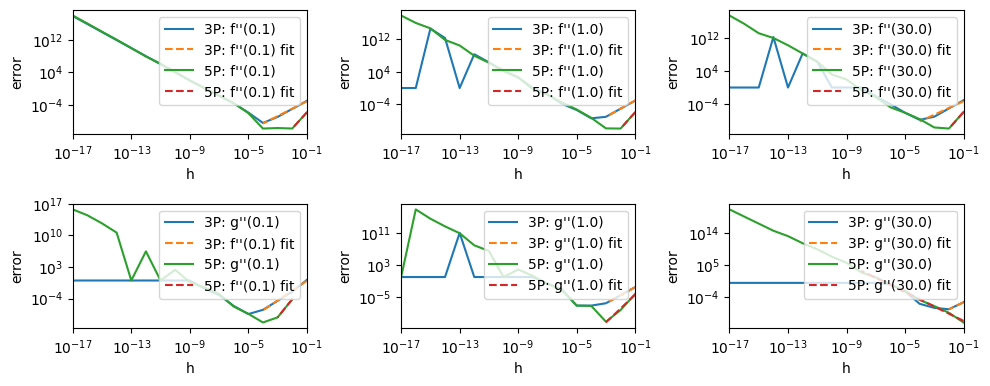

'\n\nFinal notes: \n\n* h properties for all functions for 3-point rules: \nlarge h will be the truncation region around approx  >= 10^-4 region. \nsmall h will be the roundoff regions approx <= 10^-4 region. \n\n* h properties for all functions for 5-point rules: \nlarge h will be the truncation region around approx  >= 10^-2 region. \nsmall h will be the roundoff regions approx <= 10^-2 region. \n\n\n* slopes mostly match within non-roundoff regions for 3-point p approx = 2, and 5-point \n  p approx = 4. Exeption is x = 30.0 region 5-point blows up (only get  p = -2.0) for g(x) case (reasons are that possible roundoff \nfor whole region)\n\n\n\n'

In [6]:
# 1.) Part C (bullets 3) 

import math
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 




def powerlaw(h, Y): 
    '''
    Performs a linear regression for a power law function that will be usable in log-scale fits.

    Parameters
    ----------
    N: array-like
        Independent variable values.
    Y: array-like
        Dependent variable values corresponding to h. (These are errors)

    Returns
    -------
    array-like
        generalised power law function Y = C*h**P, for log-scale purposes, will be used as a linear function. 
    '''
    
    coeffs = np.polyfit(np.log(h), np.log(Y), 1)
    p, logC = coeffs[0], coeffs[1]
    C = np.exp(logC)
    Y = C*h**p
    print("p(3P, 5P: X = 0.1, 1.0, 30.0) = ", p)
    return Y 
    











# 1 row, 3 columns of subplots
fig, axes = plt.subplots(2, 3, figsize=(10, 4))



#f(X = 0.1) and g(X = 0.1) plotting Case: 

h_vals = [] 
F_err_3P = [] 
F_err_5P = [] 
G_err_3P = [] 
G_err_5P = [] 


for i in np.arange(1, 18, 1):
    h = 0.1**i
    F_3P = three_point(f, 0.1, h)
    F_5P = five_point(f, 0.1, h)
    G_3P = three_point(g, 0.1, h)
    G_5P = five_point(g, 0.1, h)

    
    F_rel_3P = abs(F_3P - f_Double_prime(0.1))/abs(f_Double_prime(0.1))
    F_rel_5P = abs(F_5P - f_Double_prime(0.1))/abs(f_Double_prime(0.1))
    G_rel_3P = abs(G_3P - g_Double_prime(0.1))/abs(g_Double_prime(0.1))
    G_rel_5P = abs(G_5P - g_Double_prime(0.1))/abs(g_Double_prime(0.1))

    h_vals.append(h)
    F_err_3P.append(F_rel_3P)
    F_err_5P.append(F_rel_5P)
    G_err_3P.append(G_rel_3P)
    G_err_5P.append(G_rel_5P)
    

# f(x = 0.1)
axes[0,0].loglog(h_vals, F_err_3P, label = "3P: f''(0.1)")     
axes[0,0].loglog(h_vals[0:4], powerlaw(h_vals[0:4], F_err_3P[0:4]), "--", label = "3P: f''(0.1) fit")
axes[0,0].loglog(h_vals, F_err_5P, label = "5P: f''(0.1)")   
axes[0,0].loglog(h_vals[0:2], powerlaw(h_vals[0:2], F_err_5P[0:2]), "--", label = "5P: f''(0.1) fit")
axes[0,0].set_xlabel("h")
axes[0,0].set_ylabel("error")
axes[0,0].set_xlim(h_vals[-1], h_vals[0])
axes[0,0].legend(loc="best")

# g(x = 0.1)
axes[1,0].loglog(h_vals, G_err_3P, label = "3P: g''(0.1)")  
axes[1,0].loglog(h_vals[0:4], powerlaw(h_vals[0:4], G_err_3P[0:4]), "--", label = "3P: f''(0.1) fit")
axes[1,0].loglog(h_vals, G_err_5P, label = "5P: g''(0.1)")   
axes[1,0].loglog(h_vals[1:3], powerlaw(h_vals[1:3], G_err_5P[1:3]), "--", label = "5P: f''(0.1) fit")
axes[1,0].set_xlabel("h")
axes[1,0].set_ylabel("error")
axes[1,0].set_xlim(h_vals[-1], h_vals[0])
axes[1,0].legend(loc="best")




#f(X = 1.0) and g(X = 1.0) plotting Case: 

h_vals = [] 
F_err_3P = [] 
F_err_5P = [] 
G_err_3P = [] 
G_err_5P = [] 


for i in np.arange(1, 18, 1):
    h = 0.1**i
    F_3P = three_point(f, 1.0, h)
    F_5P = five_point(f, 1.0, h)
    G_3P = three_point(g, 1.0, h)
    G_5P = five_point(g, 1.0, h)

    
    F_rel_3P = abs(F_3P - f_Double_prime(1.0))/abs(f_Double_prime(1.0))
    F_rel_5P = abs(F_5P - f_Double_prime(1.0))/abs(f_Double_prime(1.0))
    G_rel_3P = abs(G_3P - g_Double_prime(1.0))/abs(g_Double_prime(1.0))
    G_rel_5P = abs(G_5P - g_Double_prime(1.0))/abs(g_Double_prime(1.0))

    h_vals.append(h)
    F_err_3P.append(F_rel_3P)
    F_err_5P.append(F_rel_5P)
    G_err_3P.append(G_rel_3P)
    G_err_5P.append(G_rel_5P)
    

# f(x = 1.0)
axes[0,1].loglog(h_vals, F_err_3P, label = "3P: f''(1.0)")   
axes[0,1].loglog(h_vals[0:3], powerlaw(h_vals[0:3], F_err_3P[0:3]), "--", label = "3P: f''(1.0) fit")  
axes[0,1].loglog(h_vals, F_err_5P, label = "5P: f''(1.0)")     
axes[0,1].loglog(h_vals[0:2], powerlaw(h_vals[0:2], F_err_5P[0:2]), "--", label = "5P: f''(1.0) fit")
axes[0,1].set_xlabel("h")
axes[0,1].set_ylabel("error")
axes[0,1].set_xlim(h_vals[-1], h_vals[0])
axes[0,1].legend(loc="best")

# g(x = 1.0)
axes[1,1].loglog(h_vals, G_err_3P, label = "3P: g''(1.0)")     
axes[1,1].loglog(h_vals[0:3], powerlaw(h_vals[0:3], G_err_3P[0:3]), "--", label = "3P: g''(1.0) fit")
axes[1,1].loglog(h_vals, G_err_5P, label = "5P: g''(1.0)")   
axes[1,1].loglog(h_vals[0:3], powerlaw(h_vals[0:3], G_err_5P[0:3]), "--", label = "5P: g''(1.0) fit")
axes[1,1].set_xlabel("h")
axes[1,1].set_ylabel("error")
axes[1,1].set_xlim(h_vals[-1], h_vals[0])
axes[1,1].legend(loc="best")






#f(X = 30.0) and g(X = 30.0) plotting Case: 

h_vals = [] 
F_err_3P = [] 
F_err_5P = [] 
G_err_3P = [] 
G_err_5P = [] 


for i in np.arange(1, 18, 1):
    h = 0.1**i
    F_3P = three_point(f, 30.0, h)
    F_5P = five_point(f, 30.0, h)
    G_3P = three_point(g, 30.0, h)
    G_5P = five_point(g, 30.0, h)

    
    F_rel_3P = abs(F_3P - f_Double_prime(30.0))/abs(f_Double_prime(30.0))
    F_rel_5P = abs(F_5P - f_Double_prime(30.0))/abs(f_Double_prime(30.0))
    G_rel_3P = abs(G_3P - g_Double_prime(30.0))/abs(g_Double_prime(30.0))
    G_rel_5P = abs(G_5P - g_Double_prime(30.0))/abs(g_Double_prime(30.0))

    h_vals.append(h)
    F_err_3P.append(F_rel_3P)
    F_err_5P.append(F_rel_5P)
    G_err_3P.append(G_rel_3P)
    G_err_5P.append(G_rel_5P)
    

# f(x = 30.0)
axes[0,2].loglog(h_vals, F_err_3P, label = "3P: f''(30.0)")   
axes[0,2].loglog(h_vals[0:4], powerlaw(h_vals[0:4], F_err_3P[0:4]), "--", label = "3P: f''(30.0) fit") 
axes[0,2].loglog(h_vals, F_err_5P, label = "5P: f''(30.0)")    
axes[0,2].loglog(h_vals[0:2], powerlaw(h_vals[0:2], F_err_5P[0:2]), "--", label = "5P: f''(30.0) fit")
axes[0,2].set_xlabel("h")
axes[0,2].set_ylabel("error")
axes[0,2].set_xlim(h_vals[-1], h_vals[0])
axes[0,2].legend(loc="best")

# g(x = 30.0)
axes[1,2].loglog(h_vals, G_err_3P, label = "3P: g''(30.0)")   
axes[1,2].loglog(h_vals[0:2], powerlaw(h_vals[0:2], G_err_3P[0:2]), "--", label = "3P: g''(30.0) fit")
axes[1,2].loglog(h_vals, G_err_5P, label = "5P: g''(30.0)")    
axes[1,2].loglog(h_vals[0:8], powerlaw(h_vals[0:8], G_err_5P[0:8]), "--", label = "5P: g''(30.0) fit")
axes[1,2].set_xlabel("h")
axes[1,2].set_ylabel("error")
axes[1,2].set_xlim(h_vals[-1], h_vals[0])
axes[1,2].legend(loc="best")




plt.tight_layout()
plt.show()





"""

Final notes: 

* h properties for all functions for 3-point rules: 
large h will be the truncation region around approx  >= 10^-4 region. 
small h will be the roundoff regions approx <= 10^-4 region. 

* h properties for all functions for 5-point rules: 
large h will be the truncation region around approx  >= 10^-2 region. 
small h will be the roundoff regions approx <= 10^-2 region. 


* slopes mostly match within non-roundoff regions for 3-point p approx = 2, and 5-point 
  p approx = 4. Exeption is x = 30.0 region 5-point blows up (only get  p = -2.0) for g(x) case (reasons are that possible roundoff 
for whole region)



"""



## Richardson extrapolation of finite differences

The central first difference of the Bessel function $f(x) = J_5(x)$ is defined by

$$
f^\prime(x) = {f(x+h/2) - f(x-h/2) \over h}
$$

with an algorithmic error of $c_1h^2$, where $c_1$ is an unknown constant. 

Calculate the first derivative at $x=2$ with an error of less than $10^{-10}$. Use Richardson extrapolation to estimate errors. To calculate the Bessel function, you may use the `scipy.special` package. That is:

```python
from scipy.special import jv, jvp  # for J_5 and its derivative
# use `jvp` for checks only
```

In [7]:
import math
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import scipy.special as sp
from scipy.special import jv, jvp 


def central_diff(f, x, h):
    '''
    Computes the central derivative for a certain x-value and specific step size.  

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 
    x : float 
        Value to which the central derivative will be applied. 
    h : float
        Step size of the central derivative.

    Returns
    -------
    float
        Approximation of the derivative evaluated at x using the central method.
    '''
    return (f(x + h/2) - f(x - h/2)) / h


def Richardson(f, x, h_1):
    '''
    Computes the Richardson extrapolation error estimate for a derivative approximation.  

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 
    x : float, or int 
        Value at which the derivative is estimated. 
    h_1 : float or numpy array
        Initial step size for the finite difference approximation.

    Returns
    -------
    float
        Absolute difference between the derivative estimates using step sizes
        h_1 and h_1/2, which serves as an error estimate.
    '''
    e1 = (f(x + h_1/2) - f(x - h_1/2)) / h_1
    h_2 = h_1/2.0 
    e2 = (f(x + h_2/2) - f(x - h_2/2)) / h_2
    rich_error = abs(e2 - e1) 
    return rich_error
    




def der_Table(W, W_prime_hat, x): 
    ''' Displays and computes the derivative methods, step sizes, and relative errors of each function case and x. 

    Parameters
    ----------
    W : function
        Python function used per data stream.
    W_prime_hat: function 
        Python defined derivatives of test functions of choice
    x: float 
        specifies data points to evaluate the derivatives.
    Returns
    -------
    Panda DataFrame
        Returns a pandas DataFrame table that displays the step sizes, relative errors, and each differentiation scheme. 
        
    '''
    Table = [] 
    for i in np.arange(5, 2, -1):
        h = 0.1**i
        Central = central_diff(W, x, h)
        rel_central = abs(Central - W_prime_hat(x))/abs(W_prime_hat(x))
        R_error = Richardson(W, x, h)
        Table.append({
            "index": i,
            "h": f"{h:1.15e}", 
            "Central": f"{Central:1.15e}", 
            "eps_rel_central": f"{rel_central :1.15e}", 
            "eps_rich": f"{R_error :1.15e}"
            
        })
    return pd.DataFrame(Table).to_string(index=False)


# Bessel term for function 
f_1 = lambda x: sp.jv(5,x) 
f_1_prime = lambda x: sp.jvp(5,x,1) 


print("j_v(x = 2.0) information for central derivative") 
print("\n", der_Table(f_1, f_1_prime, 2.0))







j_v(x = 2.0) information for central derivative

  index                     h               Central       eps_rel_central              eps_rich
     5 1.000000000000000e-05 1.639664541797786e-02 5.406038730260831e-12 8.673617379884035e-13
     4 1.000000000000000e-04 1.639664543118778e-02 8.110537143914653e-10 9.896597430447684e-12
     3 1.000000000000000e-03 1.639664674305419e-02 8.081927372991233e-08 9.938725190061781e-10


## Fourth-order finite difference approximation for the second derivative

We use Lagrangian interpolation to derive a central finite difference equation for the second derivative of a differentiable function of one variable $x$ with an error of $h^4$, where $h$ is the distance between the grid points.

(a) First, consider the error analysis discussed in class to determine the number of points you will need to obtain a formula with the required accuracy, i.e., error $\propto h^4$. Then, follow along the lines presented in class to obtain a Lagrangian interpolation with the required accuracy. 

**Hint:** This is a relatively straightforward, but lengthy calculation - so don't be discouraged along the way. You may use `sympy`. 

---------------------------------------------------------------------------------------------------------------

For time constraints, the derivation won't be shown, but I'll describe how 
I would have done it and provided logic for the number of points needed. I'll provide a citation of the finite difference form 
obtained from an online calculator, just so I can do part b. 

* The number of point needed I believe is 5-points because if you taylor expand each term and up to five points next term is 
to 6th power and divide by $h^{2}$ then h$^{4}$ error. 

* I wouldve approach this question by using defined formulas from lecture notes
$
f''(x) = \sum_{i=1}^{5} f(x_i)\, l_i''(x)
$

$
\pi(x) = (x - x_{1})(x - x_{2})(x - x_{3})(x - x_{4})(x - x_{5})
$

$
l_{i}(x) = \frac{\pi(x)}{(x - x_{i}) \, \pi'(x_{i})} \, .
$


* So I would find l-terms first, then take appropriate differentiation (same for necessary $\pi$ and $\pi$ differentiation terms (up to 2nd derivative)), then 
plug them back into the power series formula, along with substituting appropriate terms of $x_i$'s. Then I have a final difference form.  



Citation of finite difference ecalculator: 

@misc{fdcc,
  title={Finite Difference Coefficients Calculator},
  author={Taylor, Cameron R.},
  year={2016},
  howpublished="\url{https://web.media.mit.edu/~crtaylor/calculator.html}"
}


5-point formula: 


$
\frac{\partial^{(2)} f}{\partial x^{(2)}} 
\;\approx\; 
\frac{-f(x-2h) + 16f(x-h) - 30f(x) + 16f(x+h) - f(x+2h)}
{12h^{2}}
$










(b) Write a `Python` program to test your central finite difference equation and apply it to calculate the second derivative of the function $f(x) = \exp(x)$ at $x=1$. Test whether the errors are indeed of the order $h^4$.

p(5P: X = 1) =  4.0086861288069775


'\np approximately is 4 when accounted for non-roundoff error regions of the central  5-point method\n\n'

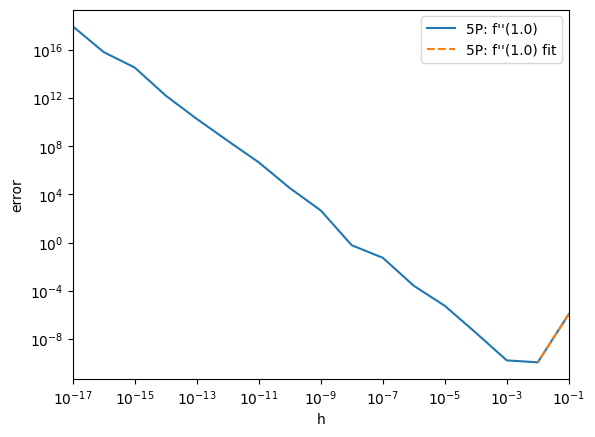

In [8]:
import math
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 



def f(x): 
    '''
    Function f is defined as cosine and can be evaluated at certain x's or gridpoints of x. 

    Parameters
    ----------
    x : int, float, or numpy array 
        Value or set of values that define f(x). 

    Returns
    -------
    int, float, or numpy array 
        Return the value or values of f(x) per each x. 
    '''
    return np.exp(x) 

def five_point(f, x, h):
    '''
    Computes the 5-point 2nd derivative for a specific x-value and a specified step size.  

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 
    x : float 
        Value to which the 5-point derivative will be applied. 
    h : float
        Step size of the 5-point derivative.

    Returns
    -------
    float
        Approximation of the derivative evaluated at x using the 5-point method.
    '''
    return (-f(x - 2*h) + 16*f(x - h) -30*f(x) + 16*f(x + h) -f(x + 2*h))/(12*h**2)


def powerlaw(h, Y): 
    '''
    Performs a linear regression for a power law function that will be usable in log-scale fits.

    Parameters
    ----------
    N: array-like
        Independent variable values.
    Y: array-like
        Dependent variable values corresponding to h. (These are errors)

    Returns
    -------
    array-like
        generalised power law function Y = C*h**P, for log-scale purposes, will be used as a linear function. 
    '''
    
    coeffs = np.polyfit(np.log(h), np.log(Y), 1)
    p, logC = coeffs[0], coeffs[1]
    C = np.exp(logC)
    Y = C*h**p
    print("p(5P: X = 1) = ", p)
    return Y 
    

#even differentiating 2-times exp is still going to be exp.


#f(X = 1.0) and g(X = 1.0) plotting Case: 

h_vals = [] 
F_err_5P = [] 



for i in np.arange(1, 18, 1):
    h = 0.1**i
    F_5P = five_point(f, 1.0, h)
    F_rel_5P = abs(F_5P - np.exp(1.0))/abs(np.exp(1.0))
    h_vals.append(h)
    F_err_5P.append(F_rel_5P)
    

# f(x = 1.0)
plt.loglog(h_vals, F_err_5P, label = "5P: f''(1.0)")     
plt.loglog(h_vals[0:2], powerlaw(h_vals[0:2], F_err_5P[0:2]), "--", label = "5P: f''(1.0) fit")
plt.xlabel("h")
plt.ylabel("error")
plt.xlim(h_vals[-1], h_vals[0])
plt.legend(loc="best")




"""
p approximately is 4 when accounted for non-roundoff error regions of the central  5-point method

"""



